## Importing required packages

In [1]:
from pathlib import Path
import pandas as pd
import joblib
import numpy as np

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone

from lazypredict.Supervised import REGRESSORS
from lazypredict import LazyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

from sklearn.metrics import mean_absolute_error


from sklearn.inspection import permutation_importance

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)

## Importing datasets, encoders & scalers:

In [2]:
artefacts_dir = Path("../artefacts")
split_dir = Path("../data/processed/eu/splits")

# load raw dataset
df_raw_dataset = pd.read_csv("../data/processed/EU/2024_FR_cleaned_final.csv")


# load raw split data (not encoded, not scaled, only split)
X_train_raw = pd.read_parquet(split_dir / "X_train_raw.parquet")
X_test_raw = pd.read_parquet(split_dir / "X_test_raw.parquet")


# load encoded split data
X_train_encoded = pd.read_parquet(split_dir / "X_train_encoded.parquet")
X_test_encoded = pd.read_parquet(split_dir / "X_test_encoded.parquet")


# load encoded and scaled split data (FOR LINEAR MODELS)
X_train_encoded_scaled = pd.read_parquet(split_dir / "X_train_encoded_scaled.parquet")
X_test_encoded_scaled = pd.read_parquet(split_dir / "X_test_encoded_scaled.parquet")

y_train = pd.read_parquet(split_dir / "y_train.parquet")["Ewltp (g/km)"]
y_test = pd.read_parquet(split_dir / "y_test.parquet")["Ewltp (g/km)"]

# load the encoder and the scaler
ohe_encoder = joblib.load(artefacts_dir / "ohe_encoder.joblib")
scaler = joblib.load(artefacts_dir / "numeric_scaler.joblib")

# Control
numeric_cols = [
    "ec (cm3)", "ep (KW)", "m (kg)", "z (Wh/km)", 
    "Electric range (km)"
]

print("X_train_encoded_scaled shape:", X_train_encoded_scaled.shape)
print("X_train_encoded_scaled columns list:", X_train_encoded_scaled.columns.tolist())
print("X_train_encoded_scaled empty data:", X_train_encoded_scaled.isna().sum().sum())
print("X_train_encoded_scaled data types:", X_train_encoded_scaled.dtypes.value_counts())
#Print verification of scaled data (mean ≈ 0, std ≈ 1)
print("X_train_encoded_scaled scaled columns mean:\n", X_train_encoded_scaled[numeric_cols].mean().round(4))
print("\nX_train_encoded_scaled scaled columns std:\n", X_train_encoded_scaled[numeric_cols].std().round(4))
print("\n*********\n")
print("X_test_encoded_scaled shape:", X_test_encoded_scaled.shape)
print("X_test_encoded_scaled columns list:", X_test_encoded_scaled.columns.tolist())
print("X_test_encoded_scaled empty data:", X_test_encoded_scaled.isna().sum().sum())
print("X_test_encoded_scaled data types:", X_test_encoded_scaled.dtypes.value_counts())


X_train_encoded_scaled shape: (91122, 28)
X_train_encoded_scaled columns list: ['ec (cm3)', 'ep (KW)', 'm (kg)', 'z (Wh/km)', 'Electric range (km)', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'T_Frequency', 'Va_Frequency', 'Ve_Frequency', 'Ct_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_diesel/electric', 'Ft_petrol', 'Ft_petrol/electric', 'Fm_H', 'Fm_M', 'Fm_P', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_none']
X_train_encoded_scaled empty data: 0
X_train_encoded_scaled data types: float64    28
Name: count, dtype: int64
X_train_encoded_scaled scaled columns mean:
 ec (cm3)               0.0000
ep (KW)                0.0000
m (kg)                -0.0000
z (Wh/km)              0.0000
Electric range (km)    0.0000
dtype: float64

X_train_encoded_scaled scaled columns std:
 ec (cm3)              1.0000
ep (KW)               1.0000
m (kg)                1.0000
z (Wh/km)             1.0000
Electric range (km)   1.0000
dtype: float64

*********

X_test_

## We want to make a quickstart with Lazypredict, let's see the list of Regressors available in Lazypredict:
(This round we will ignore our previous findings and go on with the full dataset, to validate our previous findings)

In [3]:
regressors = [
    cls
    for name, cls in REGRESSORS
]

print("Total number of available regressors:", len(regressors))
print("\nList of available regressors:\n", [cls.__name__ for cls in regressors])

Total number of available regressors: 41

List of available regressors:
 ['AdaBoostRegressor', 'BaggingRegressor', 'BayesianRidge', 'DecisionTreeRegressor', 'DummyRegressor', 'ElasticNet', 'ElasticNetCV', 'ExtraTreeRegressor', 'ExtraTreesRegressor', 'GammaRegressor', 'GaussianProcessRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'HuberRegressor', 'KNeighborsRegressor', 'KernelRidge', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LinearSVR', 'MLPRegressor', 'NuSVR', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveRegressor', 'PoissonRegressor', 'QuantileRegressor', 'RANSACRegressor', 'RandomForestRegressor', 'Ridge', 'RidgeCV', 'SGDRegressor', 'SVR', 'TransformedTargetRegressor', 'TweedieRegressor', 'LGBMRegressor']


## Let's calculate our Kernel Matrix:

In [4]:
n = len(X_train_encoded_scaled)

print(f"Training samples: {n:,}")
print(f"Kernel matrix entries: {n:,} x {n:,}")
print(f"Kernel matrix memory (float64): {n*n*8 / 1024**4:.2f} TB")

Training samples: 91,122
Kernel matrix entries: 91,122 x 91,122
Kernel matrix memory (float64): 0.06 TB


## - **1 TB = 1024 GB**
## - **0.06 TB ~=0.06x1024 ~=61.44GB**
### That means if we use Kernel PCA, Kernel SVM, Gaussian Processes etc., we'll need approximately 61.44GB+ RAM
### My computer has only 32GB of ram :)
###  Let's remove some of these from the list of models to be executed in Lazypredict and create a safe_regressors list:

In [5]:
# Exclude some troublesome regressors
safe_regressors = [
    cls
    for name, cls in REGRESSORS
    if ((name != "GaussianProcessRegressor") and (name != "KernelRidge") and (name != "NuSVR") and (name != "QuantileRegressor") and (name != "SVR"))
]

print("Total number of available regressors:", len(REGRESSORS))
print("\nList of safe regressors:\n", [cls.__name__ for cls in safe_regressors])


# Wrap each regressor so we can see which model is currently running
def make_verbose_regressor(cls):
    class VerboseRegressor(cls):
        def fit(self, X, y, *args, **kwargs):
            print(f"\n>>> STARTING: {cls.__name__}", flush=True)
            result = super().fit(X, y, *args, **kwargs)
            print(f">>> FINISHED: {cls.__name__}", flush=True)
            return result

    VerboseRegressor.__name__ = cls.__name__
    VerboseRegressor.__qualname__ = cls.__qualname__

    return VerboseRegressor


verbose_regressors = [
    make_verbose_regressor(cls)
    for cls in safe_regressors
]


reg = LazyRegressor(
    verbose=1,
    ignore_warnings=True,
    regressors=verbose_regressors,
)

models, predictions = reg.fit(
    X_train_encoded_scaled,
    X_test_encoded_scaled,
    y_train,
    y_test,
)

models

Total number of available regressors: 41

List of safe regressors:
 ['AdaBoostRegressor', 'BaggingRegressor', 'BayesianRidge', 'DecisionTreeRegressor', 'DummyRegressor', 'ElasticNet', 'ElasticNetCV', 'ExtraTreeRegressor', 'ExtraTreesRegressor', 'GammaRegressor', 'GradientBoostingRegressor', 'HistGradientBoostingRegressor', 'HuberRegressor', 'KNeighborsRegressor', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LinearSVR', 'MLPRegressor', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveRegressor', 'PoissonRegressor', 'RANSACRegressor', 'RandomForestRegressor', 'Ridge', 'RidgeCV', 'SGDRegressor', 'TransformedTargetRegressor', 'TweedieRegressor', 'LGBMRegressor']


  0%|          | 0/36 [00:00<?, ?it/s]


>>> STARTING: AdaBoostRegressor
>>> FINISHED: AdaBoostRegressor

>>> STARTING: BaggingRegressor
>>> FINISHED: BaggingRegressor

>>> STARTING: BayesianRidge
>>> FINISHED: BayesianRidge

>>> STARTING: DecisionTreeRegressor
>>> FINISHED: DecisionTreeRegressor

>>> STARTING: DummyRegressor
>>> FINISHED: DummyRegressor

>>> STARTING: ElasticNet
>>> FINISHED: ElasticNet

>>> STARTING: ElasticNetCV
>>> FINISHED: ElasticNetCV

>>> STARTING: ExtraTreeRegressor
>>> FINISHED: ExtraTreeRegressor

>>> STARTING: ExtraTreesRegressor
>>> FINISHED: ExtraTreesRegressor

>>> STARTING: GammaRegressor
>>> FINISHED: GammaRegressor

>>> STARTING: GradientBoostingRegressor
>>> FINISHED: GradientBoostingRegressor

>>> STARTING: HistGradientBoostingRegressor
>>> FINISHED: HistGradientBoostingRegressor

>>> STARTING: HuberRegressor
>>> FINISHED: HuberRegressor

>>> STARTING: KNeighborsRegressor
>>> FINISHED: KNeighborsRegressor

>>> STARTING: Lars
>>> FINISHED: Lars

>>> STARTING: LarsCV
>>> FINISHED: LarsCV

>

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
ExtraTreesRegressor,0.9990,0.9990,1.8022,12.6181
RandomForestRegressor,0.9988,0.9988,1.9816,23.0601
BaggingRegressor,0.9987,0.9987,2.0602,2.3283
ExtraTreeRegressor,0.9985,0.9985,2.1630,0.1969
DecisionTreeRegressor,0.9981,0.9981,2.4399,0.3774
KNeighborsRegressor,0.9979,0.9979,2.6124,0.7674
LGBMRegressor,0.9972,0.9973,2.9610,0.9216
HistGradientBoostingRegressor,0.9972,0.9972,2.9709,1.1110
MLPRegressor,0.9958,0.9958,3.6403,19.7227


## Our top 2 models are:
#### - ExtraTreesRegressor (Adjusted R-Squared: 0.9990, R-Squared: 0.9990, RMSE: 1.7497)
#### - RandomForestRegressor (Adjusted R-Squared: 0.9988, R-Squared: 0.9988, RMSE: 1.9043)

#### Furthermore, it looks like non-linear models are more successful than the linear ones.

## We've got suspiciously good results. We're gonna have to investigate this.

In [6]:
print(y_train.describe())
print()
print(y_test.describe())
print()

print("Calculating y_test standard deviation:")
y_test_std = y_test.std()
print("y_test standard deviation:", y_test_std)

rmse_extra_trees = 2.308104
rmse_random_forest = 2.361942
print("Normalized RMSE (Extra Trees):", rmse_extra_trees / y_test.std())
print("Normalized RMSE (Random Forest):", rmse_random_forest / y_test.std())



count   91122.0000
mean      101.8452
std        56.5118
min         7.0000
25%        35.0000
50%       127.0000
75%       141.0000
max       456.0000
Name: Ewltp (g/km), dtype: float64

count   22746.0000
mean      101.6558
std        56.4891
min         6.0000
25%        35.0000
50%       127.0000
75%       140.0000
max       448.0000
Name: Ewltp (g/km), dtype: float64

Calculating y_test standard deviation:
y_test standard deviation: 56.48905680523432
Normalized RMSE (Extra Trees): 0.04085931206035165
Normalized RMSE (Random Forest): 0.04181238161124936


#### The standard deviation of the test set for the Ewltp (g/km) target is 55.18 g/km, while the Random Forest RMSE is 1.9043 g/km. 
#### The normalized RMSE is 0.043; therefore, the model’s error is only about 4.3% of the target’s natural variability. 
#### This is consistent with the R-Squared = 0.999 result; however, due to the exceptionally high performance, feature leakage, target proxies, and train-test similarity should be examined further.

## Let's see feature importances for these 2 models:

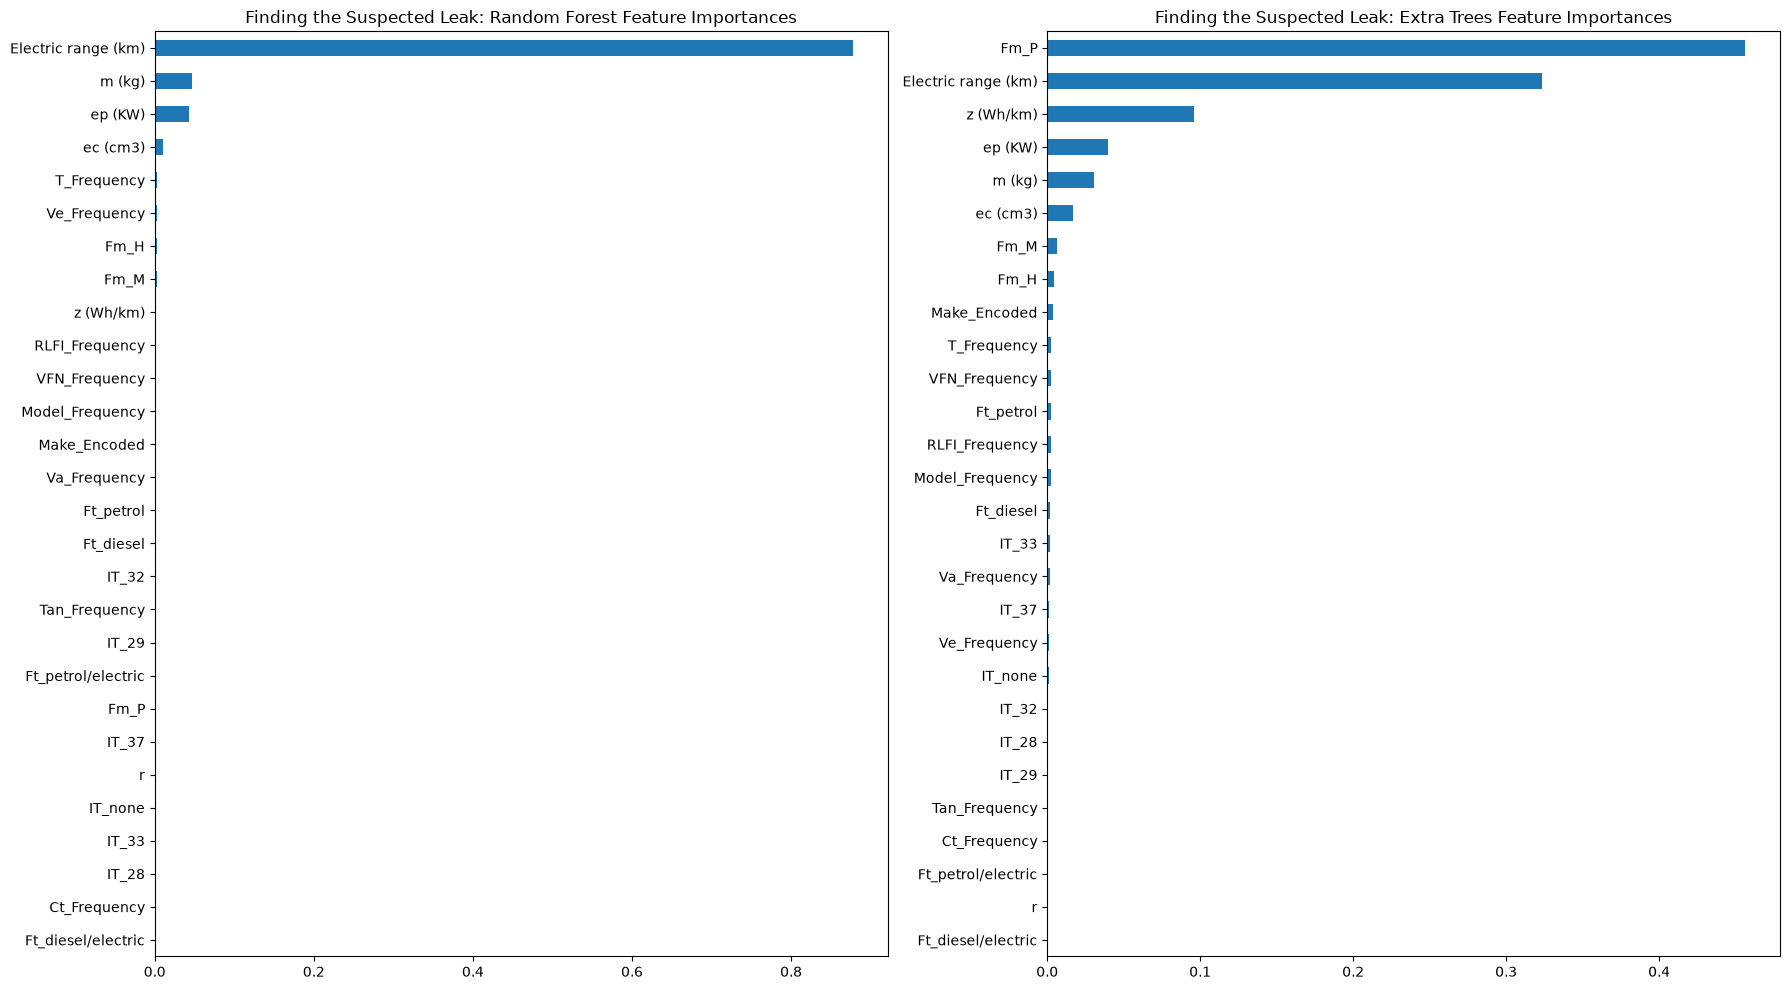

In [7]:
# Retrieve the models trained by LazyPredict as a dictionary
trained_models = reg.provide_models(
    X_train_encoded_scaled,
    X_test_encoded_scaled,
    y_train,
    y_test,
)

# Get the fitted pipelines from LazyPredict
rf_pipeline = trained_models["RandomForestRegressor"]
et_pipeline = trained_models["ExtraTreesRegressor"]

# Get the actual sklearn RandomForestRegressor and ExtraTreesRegressor objects from the pipeline
rf = rf_pipeline.named_steps["regressor"]
et = et_pipeline.named_steps["regressor"]

# Let's visualize the feature importances
rf_importances = pd.Series(
    rf.feature_importances_,
    index=X_train_encoded_scaled.columns
)
et_importances = pd.Series(
    et.feature_importances_,
    index=X_train_encoded_scaled.columns
)

# Create side-by-side plots
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 10),
    sharex=False
)


rf_importances.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Finding the Suspected Leak: Random Forest Feature Importances")

et_importances.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Finding the Suspected Leak: Extra Trees Feature Importances")

plt.tight_layout()
plt.show();

## Looks like we have our first candidate to investigate:
- Electric range (km) is in top 3 for both regressors, with ~87% feature importance for Random Forest Regressor.

We could interpret this as:
- Electric range (km) is truly a very powerful physical explanation for the target.
- Electric range (km) is either used directly in the calculation of the WLTP CO2 target or serves as a proxy that is very close to the target.

### First thing first about the Electric range (km) column; we know that our dataset contain Fuel and Hybrid vehicles hence we expect the Fuel vehicles to have Electric range (km) = 0.
Let's see this distribution and see the comparison for Electric range (km) = 0 & Electric range (km) > 0

In [8]:
electric_range = df_raw_dataset["Electric range (km)"]

print("Total number of rows:", len(electric_range))
print("Number of missing values (NaN):", electric_range.isna().sum())
print("Number of rows with 0 km:", (electric_range == 0).sum())
print("Number of rows with more than 0 km:", (electric_range > 0).sum())

print("\nSummary of positive electric range values:")
print(electric_range[electric_range > 0].describe())

Total number of rows: 113868
Number of missing values (NaN): 0
Number of rows with 0 km: 76298
Number of rows with more than 0 km: 37570

Summary of positive electric range values:
count   37570.0000
mean       81.6092
std        25.6262
min        11.0000
25%        59.0000
50%        76.0000
75%       105.0000
max       143.0000
Name: Electric range (km), dtype: float64


In [9]:
comparison_zero_vs_positive = (
    df_raw_dataset
    .assign(
        electric_range_group=lambda data:
        data["Electric range (km)"].gt(0).map({
            False: "0 km",
            True: "Greater than 0 km",
        })
    )
    .groupby("electric_range_group")["Ewltp (g/km)"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

comparison_zero_vs_positive

,count,mean,median,std,min,max
electric_range_group,,,,,,
0 km,76298,138.5951,135.1802,23.9743,87.0000,456.0000
Greater than 0 km,37570,27.0979,26.0000,13.4299,6.0000,276.0000


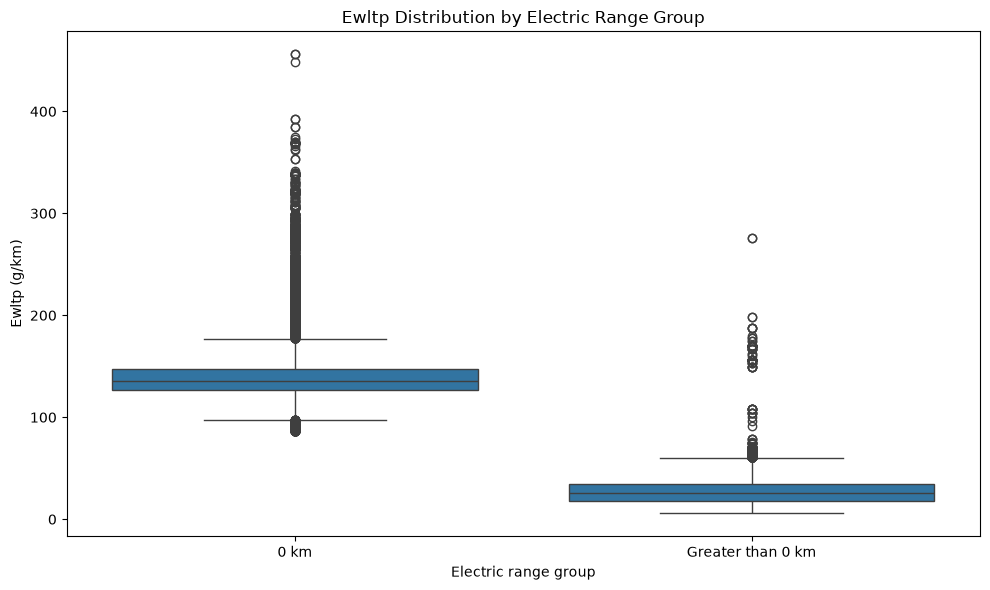

In [10]:
plot_data = df_raw_dataset.assign(
    electric_range_group=lambda data:
    data["Electric range (km)"].gt(0).map({
        False: "0 km",
        True: "Greater than 0 km",
    })
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="electric_range_group",
    y="Ewltp (g/km)"
)

plt.title("Ewltp Distribution by Electric Range Group")
plt.xlabel("Electric range group")
plt.ylabel("Ewltp (g/km)")
plt.tight_layout()
plt.show()

### The box plot clearly shows that the "Electric range = 0" and "Electric range > 0" groups behave like two distributions that are almost completely distinct in terms of Ewltp.

- The center of the 0 km group is around 135 g/km.
- The center of the group greater than 0 km is around 28 g/km.
- There is very little overlap between the two boxes.
- The outliers in the 0 km group are mostly high emissions above approximately 175 g/km.
- Outliers in the positive range group may be hybrid vehicles with higher emissions or examples of different vehicle types.

### Therefore, it now makes sense that the Random Forest assigns approximately 87% importance to the “Electric range (km)” feature. The model is largely able to learn this simple distinction:
- Electric range == 0 **then** Ewltp is mostly high
- Electric range > 0 **then** Ewltp is mostly low

### This shows that the Electric range is a strong **proxy**. However, we are not yet saying that this is a leakage, because the Electric range may be a vehicle characteristic that is actually known and physically meaningful at the time of estimation.

### Now we'll see if there's a relationship between the positive range value and the Ewltp:

In [11]:
positive_range_data = df_raw_dataset[
    df_raw_dataset["Electric range (km)"] > 0
][
    ["Electric range (km)", "Ewltp (g/km)"]
]

print("Number of rows in the 'Positive' Electric range:", len(positive_range_data))

print("\nPearson correlation:")
print(
    positive_range_data[
        ["Electric range (km)", "Ewltp (g/km)"]
    ].corr(method="pearson")
)

print("\nSpearman correlation:")
print(
    positive_range_data[
        ["Electric range (km)", "Ewltp (g/km)"]
    ].corr(method="spearman")
)

Number of rows in the 'Positive' Electric range: 37570

Pearson correlation:
                     Electric range (km)  Ewltp (g/km)
Electric range (km)               1.0000       -0.8078
Ewltp (g/km)                     -0.8078        1.0000

Spearman correlation:
                     Electric range (km)  Ewltp (g/km)
Electric range (km)               1.0000       -0.8958
Ewltp (g/km)                     -0.8958        1.0000


### This result shows that there is a very strong inverse relationship between electric range (km) and Ewltp (g/km) even within the group of electric vehicles. In other words, the model does not merely distinguish between **“does the vehicle have an electric range or not?”**; it also learns that emissions systematically decrease as the range increases.

- Pearson correlation: -0.7856 -> A strong, inverse, and partially linear relationship
- Spearman correlation: -0.8760 -> A very strong inverse sequential/monotonic relationship

### Preliminary Results So Far

We currently have three strong findings:

    - In 70% of the dataset, the electric range is 0 km.

    - The 0 km group averages 138.4 g/km, while the positive-range group averages 28.3 g/km.

    - Even in vehicles with a positive range, Ewltp decreases significantly as the range increases.

### Therefore, the high feature importance of “Electric range” is not unreasonable. But there is still one critical question to determine whether this is a case of leakage: How much does performance drop when the "Electric range (km)" feature is removed from the model?

In [12]:
# check which exact parameters were used in the Lazypredict for the RandomForestRegressor
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [14]:
base_model = RandomForestRegressor(
    bootstrap=True,
    ccp_alpha=0.0,
    criterion='squared_error',
    max_depth=None,
    max_features=1.0,
    max_leaf_nodes=None,
    max_samples=None,
    min_impurity_decrease=0.0,
    min_samples_leaf=1,
    min_samples_split=2,
    min_weight_fraction_leaf=0.0,
    monotonic_cst=None,
    n_estimators=100,
    n_jobs=None,
    oob_score=False,
    random_state=42,
    verbose=0,
    warm_start=False
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

X_fs = X_train_encoded_scaled.copy()
y_fs = y_train.copy()

feature_sets = []
cv_results = []

while X_fs.shape[1] >= 2:

    fold_mae = []
    fold_importances = []

    for train_idx, valid_idx in cv.split(X_fs):

        X_fold_train = X_fs.iloc[train_idx]
        X_fold_valid = X_fs.iloc[valid_idx]

        y_fold_train = y_fs.iloc[train_idx]
        y_fold_valid = y_fs.iloc[valid_idx]

        model = clone(base_model)
        model.fit(X_fold_train, y_fold_train)

        pred = model.predict(X_fold_valid)

        fold_mae.append(
            mean_absolute_error(y_fold_valid, pred)
        )

        perm = permutation_importance(
            model,
            X_fold_valid,
            y_fold_valid,
            scoring="neg_mean_absolute_error",
            n_repeats=5,
            random_state=42,
            n_jobs=-1,
        )

        fold_importances.append(perm.importances_mean)

    mean_mae = np.mean(fold_mae)
    std_mae = np.std(fold_mae)

    mean_importance = np.mean(
        fold_importances,
        axis=0
    )

    current_features = list(X_fs.columns)

    feature_sets.append(
        current_features.copy()
    )

    cv_results.append({
        "n_features": len(current_features),
        "features": current_features.copy(),
        "cv_mae_mean": mean_mae,
        "cv_mae_std": std_mae,
    })

    weakest_idx = np.argmin(mean_importance)
    weakest_feature = current_features[weakest_idx]

    print(
        f"{len(current_features)} features | "
        f"CV MAE: {mean_mae:.6f} ± {std_mae:.6f} | "
        f"Removing: {weakest_feature}"
    )

    X_fs = X_fs.drop(
        columns=[weakest_feature]
    )

results_df = pd.DataFrame(cv_results)

best_row = results_df.loc[
    results_df["cv_mae_mean"].idxmin()
]

best_features = best_row["features"]

print("\nBest number of features:", best_row["n_features"])
print("Best CV MAE:", best_row["cv_mae_mean"])
print("Best features:")
print(best_features)

28 features | CV MAE: 0.920933 ± 0.008081 | Removing: Ft_diesel/electric
27 features | CV MAE: 0.920765 ± 0.008350 | Removing: Ct_Frequency
26 features | CV MAE: 0.920681 ± 0.008013 | Removing: IT_28
25 features | CV MAE: 0.920338 ± 0.008202 | Removing: IT_33
24 features | CV MAE: 0.920135 ± 0.008473 | Removing: Ft_petrol/electric
23 features | CV MAE: 0.920606 ± 0.008303 | Removing: Fm_P
22 features | CV MAE: 0.920501 ± 0.008307 | Removing: r
21 features | CV MAE: 0.939588 ± 0.006750 | Removing: IT_none
20 features | CV MAE: 0.939747 ± 0.006734 | Removing: Tan_Frequency
19 features | CV MAE: 0.915298 ± 0.007231 | Removing: IT_37
18 features | CV MAE: 0.921556 ± 0.006096 | Removing: IT_29
17 features | CV MAE: 0.921827 ± 0.006144 | Removing: IT_32
16 features | CV MAE: 0.923339 ± 0.006931 | Removing: Ft_diesel
15 features | CV MAE: 0.923278 ± 0.006096 | Removing: Va_Frequency
14 features | CV MAE: 0.926652 ± 0.006244 | Removing: Make_Encoded


/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/lok

13 features | CV MAE: 0.846980 ± 0.004693 | Removing: Model_Frequency


/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/lok

12 features | CV MAE: 0.854417 ± 0.004832 | Removing: Ft_petrol


/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Users/serhatgemici/Documents/Liora/jul26_bds_int_co2/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


11 features | CV MAE: 0.855948 ± 0.006765 | Removing: VFN_Frequency
10 features | CV MAE: 0.891831 ± 0.006633 | Removing: Ve_Frequency
9 features | CV MAE: 1.266796 ± 0.008609 | Removing: z (Wh/km)
8 features | CV MAE: 1.310462 ± 0.007969 | Removing: RLFI_Frequency
7 features | CV MAE: 1.418750 ± 0.011139 | Removing: Fm_H
6 features | CV MAE: 1.418562 ± 0.011076 | Removing: T_Frequency
5 features | CV MAE: 1.481662 ± 0.012343 | Removing: Fm_M
4 features | CV MAE: 1.526324 ± 0.009990 | Removing: ec (cm3)
3 features | CV MAE: 1.860087 ± 0.020779 | Removing: ep (KW)
2 features | CV MAE: 4.578901 ± 0.047223 | Removing: m (kg)

Best number of features: 13
Best CV MAE: 0.8469796074277927
Best features:
['ec (cm3)', 'ep (KW)', 'm (kg)', 'z (Wh/km)', 'Electric range (km)', 'Model_Frequency', 'VFN_Frequency', 'T_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'Ft_petrol', 'Fm_H', 'Fm_M']


# Let's stop this notebook here, export our datasets and start a fresh notebook:

In [15]:
split_dir = Path("../data/processed/eu/splits")

# If the folder doesn't exist, create it; if it does exist, don't return an error
split_dir.mkdir(parents=True, exist_ok=True)

# save encoded and scaled split data
X_train_encoded_scaled.to_parquet(split_dir / "X_train_group_encoded_scaled.parquet", index=True)
X_test_encoded_scaled.to_parquet(split_dir / "X_test_group_encoded_scaled.parquet", index=True)

y_train.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train.parquet", index=True)
y_test.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test.parquet", index=True)

# control
print("X_train_encoded_scaled saved:", (split_dir / "X_train_group_encoded_scaled.parquet").exists())
print("X_test_encoded_scaled saved:", (split_dir / "X_test_group_encoded_scaled.parquet").exists())
print("******")
print("y_train saved:", (split_dir / "y_train.parquet").exists())
print("y_test saved:", (split_dir / "y_test.parquet").exists())

X_train_encoded_scaled saved: True
X_test_encoded_scaled saved: True
******
y_train saved: True
y_test saved: True


# Summary
## 1. Loaded the Cleaned Data
* It imported the prepared dataset containing 114,871 car records divided into:
* Training Set (91,896 cars): The historical data used to teach the models.
* Testing Set (22,975 cars): Hidden data used to test if the models actually learned or just memorized.
* 19 Features (X): Vehicle mass, power, engine capacity, battery consumption, etc.
* 1 Target (y): Official CO2 emissions in g/km (Ewltp (g/km)).

## 2. Ran a Computer Safety Check
* Before training heavy algorithms, checks to see how much computer memory (RAM) certain models would need.

* It calculated that math-heavy models (**like Gaussian Processors**) would require 61.44 GB of RAM to process 91,896 rows.

* To prevent the computer from freezing or crashing, it automatically kicked out those memory-hungry models before starting.

## 3. Trained 36 Different Models Automatically (LazyPredict)
Instead of writing code for 36 models one by one, the notebook used a tool called LazyPredict. It threw all 88.760 cars at 36 distinct algorithms (Linear Regression, Decision Trees, Random Forests, Gradient Boosters, etc.) and said:
"Learn the pattern between these specs and CO2, then guess the CO2 for the 22.129 test cars."

## 4. Ranked the Models by Accuracy

Each model was evaluated based on how closely its predictions matched the actual vehicle CO₂ emissions. The models were ranked using **RMSE**, **R²**, **Adjusted R²**, and training time.

### The Winners: Tree-Based Ensemble Models

**ExtraTreesRegressor** achieved the best overall performance:

- **RMSE:** 1.7497 g/km
- **R²:** 0.9990
- **Adjusted R²:** 0.9990
- **Training time:** 10.6061 seconds

This means that the model's predictions were, on average, only approximately **1.75 g/km away** from the actual CO₂ emissions. Its R² score of **0.9990** indicates that it explained approximately **99.9% of the variation** in CO₂ emissions.

The next-best models were:

| Rank | Model | RMSE (g/km) | R² | Adjusted R² | Time (s) |
|---:|---|---:|---:|---:|---:|
| 1 | ExtraTreesRegressor | 1.7497 | 0.9990 | 0.9990 | 10.6061 |
| 2 | RandomForestRegressor | 1.9043 | 0.9988 | 0.9988 | 19.2875 |
| 3 | BaggingRegressor | 1.9390 | 0.9988 | 0.9988 | 2.0263 |
| 4 | ExtraTreeRegressor | 2.0214 | 0.9987 | 0.9987 | 0.1333 |
| 5 | DecisionTreeRegressor | 2.2798 | 0.9983 | 0.9983 | 0.3135 |

Although **RandomForestRegressor** had a very similar R² score, ExtraTreesRegressor produced the lowest RMSE and was therefore the most accurate model in this evaluation.

### Target Metrics

The target variable, CO₂ emissions, had the following distribution:

- **Mean CO₂ emissions:** 104.84 g/km
- **Standard deviation:** 54.88 g/km

### Relative Error Calculation

To put the RMSE into context, the normalized RMSE was calculated by dividing the model's RMSE by the standard deviation of the target variable:

$$
\text{Normalized RMSE}
=
\frac{\text{RMSE}}{\sigma_{\text{target}}}
=
\frac{1.7497}{54.88}
\approx 3.19\%
$$

Therefore, the ExtraTreesRegressor's RMSE was approximately **3.19% of the natural variation** in the target variable.

### Key Finding

The tree-based models performed substantially better than the linear models. ExtraTreesRegressor achieved an R² score of **0.9990** and an RMSE of **1.7497 g/km**, while LinearRegression achieved an R² score of **0.9630** and an RMSE of **10.6212 g/km**.

This suggests that the relationship between the vehicle features and CO₂ emissions is largely **non-linear**, which allows tree-based ensemble models to capture the underlying patterns more effectively than traditional linear regression models.


## 5. Flagged a Potential Warning (Data Leakage)

Because an error of just **1.7497 g/km is extremely low**, it is recommended to double-check for data leakage—meaning some input feature might be secretly giving away the answer to the target variable.

An $R^2 = 0.9990$ is suspiciously high for real-world environmental and automotive testing data. Key issues to audit in the preprocessing pipeline:

* Target Proxies: Features such as electric energy consumption (z (Wh/km)) or engine size (ec (cm3)) combined with vehicle mass (m (kg)) closely mirror the deterministic physical formula used during WLTP laboratory testing.
  
* Model/Make Target Encoding Leakage: If target encoding for high-cardinality features (Make_Encoded, Model_Frequency) was computed before splitting into train/test sets, target information directly leaked into the validation set.

*  Group Overlap (Train/Test Leakage): Vehicle variants with identical configurations may exist across both splits. If a standard random split was used instead of a GroupShuffleSplit (e.g., grouping by vehicle Model or Type-Approval), the test set may simply be memorised identical duplicates of training samples.   

## 6. Audit Feature Encoding (Feature Importance)
Re-verify that target encoders were fitted strictly on X_train and merely transformed onto X_test.
* Implement Grouped Splitting: Group data by Model or Make using GroupShuffleSplit so the test set evaluates unseen car models.
  
*  Feature Importance and SHAP: Run SHAP or permutation importance to verify if a single feature (e.g., z (Wh/km) or m (kg)) is artificially dictating predictions.

*  Hyperparameter Tuning: Tune the top-performing model (RandomForestRegressor) using cross-validation on the corrected split
